In [56]:
# Import necessary libraries for data manipulation, financial analysis, HMM, and plotting
import warnings
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from scipy.optimize import minimize
from pathlib import Path
warnings.filterwarnings("ignore")

In [57]:
# Define tickers for assets (SPY, TLT, GLD, VIX) and download historical daily closing prices
# Calculate log returns, rolling volatilities (20-day and 63-day), and momentum (20-day and 63-day)
# Also compute rolling correlation between SPY and TLT, and add VIX level as features
TICKERS = ["SPY", "TLT", "GLD", "^VIX"]

prices = yf.download(
    TICKERS,
    start="2005-01-01",
    end="2026-06-30",
    auto_adjust=True,
    progress=False)["Close"]

prices = prices.dropna()
log_returns = np.log(prices / prices.shift(1))
log_returns = log_returns.dropna()

rolling_vol = log_returns["SPY"].rolling(window=63).std() * np.sqrt(252)

rolling_mean = log_returns["SPY"].rolling(window=252).mean()

rolling_var = log_returns["SPY"].rolling(window=252).var()

features = log_returns.copy()

features.columns = [
    "GLD_Return",
    "SPY_Return",
    "TLT_Return",
    "VIX_Return"]

# 20-day rolling volatility
rolling_vol_20 = features.rolling(window=20).std()

rolling_vol_20.columns = ["GLD_Vol20","SPY_Vol20","TLT_Vol20","VIX_Vol20"]

features = pd.concat([features, rolling_vol_20],axis=1)

features = features.dropna()

rolling_vol_63 = (features[["GLD_Return", "SPY_Return", "TLT_Return", "VIX_Return"]].rolling(window=63).std())
rolling_vol_63.columns = ["GLD_Vol63","SPY_Vol63","TLT_Vol63","VIX_Vol63",]

features = pd.concat([features, rolling_vol_63],axis=1)

features = features.dropna()

# 20-Day Momentum
momentum_20 = (prices.pct_change(periods=20))
momentum_20.columns = ["GLD_Mom20","SPY_Mom20","TLT_Mom20","VIX_Mom20"] # Renaming for consistency

momentum_63 = (prices.pct_change(periods=63))
momentum_63.columns = [
    "GLD_Mom63",
    "SPY_Mom63",
    "TLT_Mom63",
    "VIX_Mom63"]

momentum_20 = momentum_20.loc[features.index]
momentum_63 = momentum_63.loc[features.index]

features = pd.concat([features,momentum_20,momentum_63],axis=1)
features = features.dropna()

rolling_corr_spy_tlt = (
    features["SPY_Return"]
    .rolling(window=20)
    .corr(features["TLT_Return"]))

rolling_corr_spy_tlt.name = "SPY_TLT_Corr20"
features = pd.concat([features, rolling_corr_spy_tlt],axis=1)
features = features.dropna()
vix_level = prices["^VIX"].loc[features.index]
features["VIX_Level"] = vix_level

In [58]:
# Define the list of observation features to be used by the HMM model
# Select these features from the 'features' DataFrame and create a copy 'X'
observation_features = [
    "SPY_Return",
    "TLT_Return",

    "SPY_Vol20",
    "SPY_Vol63",

    "TLT_Vol20",
    "TLT_Vol63",

    "SPY_Mom20",
    "SPY_Mom63",

    "TLT_Mom20",
    "TLT_Mom63",

    "SPY_TLT_Corr20",

    "VIX_Level"]

X = features[observation_features].copy()

In [59]:
# Initialize a StandardScaler to normalize the observation features
# Fit the scaler to 'X' and transform the data, then convert it back to a DataFrame
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=observation_features)

In [92]:
# Define a range of candidate hidden states for the HMM
# Iterate through each candidate, train a GaussianHMM model, and evaluate it using Log-Likelihood, AIC, and BIC
# Store the results and the trained models in dictionaries
candidate_states = [2,3,4,5]
model_results = []
trained_models = {}
for n_states in candidate_states:

    model = GaussianHMM(n_components=n_states,covariance_type="full",n_iter=1000,random_state=12)

    model.fit(X_scaled)

    log_likelihood = model.score(X_scaled)

    n_features = X_scaled.shape[1]
    # Number of free parameters: transition matrix, means, and covariance matrices
    n_parameters = ((n_states - 1) + n_states * (n_states - 1) + n_states * n_features
        + n_states * n_features * (n_features + 1) / 2)

    n_samples = X_scaled.shape[0]
    aic = 2 * n_parameters - 2 * log_likelihood
    bic = (np.log(n_samples) * n_parameters - 2 * log_likelihood)

    model_results.append({
        "States": n_states,
        "LogLikelihood": log_likelihood,
        "Parameters": int(n_parameters),
        "AIC": aic,
        "BIC": bic,
        "Converged": model.monitor_.converged})

    trained_models[n_states] = model

In [62]:
# Select the best HMM model (in this case, the one with 5 states)
# Predict the hidden states (regimes) for the scaled data and count the occurrences of each state
best_model = trained_models[5]
hidden_states = best_model.predict(X_scaled)
state_counts = (pd.Series(hidden_states).value_counts().sort_index())

In [63]:
# Define the portfolio assets to be analyzed
# Add the predicted hidden states as a 'Regime' column to the features DataFrame
# Group asset returns by regime and store them in a dictionary for further analysis
portfolio_assets = ["SPY_Return", "TLT_Return", "GLD_Return"]

features["Regime"] = hidden_states

regime_returns = {}
for regime in sorted(features["Regime"].unique()):

    regime_data = features.loc[features["Regime"] == regime, portfolio_assets]

    regime_returns[regime] = regime_data.copy()

In [64]:
# Print the number of observations (data points) for each identified market regime
for regime, data in regime_returns.items():
    print(f"Regime {regime}: {len(data)} observations")

Regime 0: 1318 observations
Regime 1: 678 observations
Regime 2: 1208 observations
Regime 3: 180 observations
Regime 4: 1920 observations


In [65]:
# Display the first few rows of asset returns for Regime 3 to inspect its data
regime_returns[3].head()

,SPY_Return,TLT_Return,GLD_Return
Date,,,
2008-09-17,-0.046005,0.004988,0.106974
2008-09-18,0.029240,-0.014729,-0.031620
2008-09-19,0.038946,-0.032251,0.037687
2008-09-22,-0.022900,-0.000106,0.036542
2008-09-23,-0.023014,-0.003838,-0.009690


In [66]:
# Calculate the mean returns for each asset within each identified market regime
regime_mean_returns = {}

for regime, data in regime_returns.items():

    regime_mean_returns[regime] = data.mean()

In [67]:
# Print the mean returns for each asset, organized by market regime
for regime in regime_mean_returns:

    print(
f"\nRegime {regime}")
    print(regime_mean_returns[regime])


Regime 0
SPY_Return    0.000378
TLT_Return   -0.000324
GLD_Return    0.000022
dtype: float64

Regime 1
SPY_Return    0.000726
TLT_Return   -0.000257
GLD_Return    0.000146
dtype: float64

Regime 2
SPY_Return    0.000240
TLT_Return    0.000752
GLD_Return    0.000469
dtype: float64

Regime 3
SPY_Return   -0.002902
TLT_Return    0.002318
GLD_Return    0.002313
dtype: float64

Regime 4
SPY_Return    0.000756
TLT_Return   -0.000060
GLD_Return    0.000556
dtype: float64


In [68]:
# Create a DataFrame from the regime mean returns, transpose it, and name the index 'Regime'
mean_return_table = (pd.DataFrame(regime_mean_returns).T)
mean_return_table.index.name = "Regime"
mean_return_table

,SPY_Return,TLT_Return,GLD_Return
Regime,,,
0,0.000378,-0.000324,0.000022
1,0.000726,-0.000257,0.000146
2,0.000240,0.000752,0.000469
3,-0.002902,0.002318,0.002313
4,0.000756,-0.000060,0.000556


In [69]:
# Calculate the covariance matrix for asset returns within each identified market regime
regime_covariance = {}

for regime, data in regime_returns.items():

    regime_covariance[regime] = data.cov()

In [70]:
# Display the covariance matrix for Regime 3 to inspect asset relationships within that regime
regime_covariance[3]

,SPY_Return,TLT_Return,GLD_Return
SPY_Return,0.001505,-0.000352,0.000050
TLT_Return,-0.000352,0.000379,0.000056
GLD_Return,0.000050,0.000056,0.000567


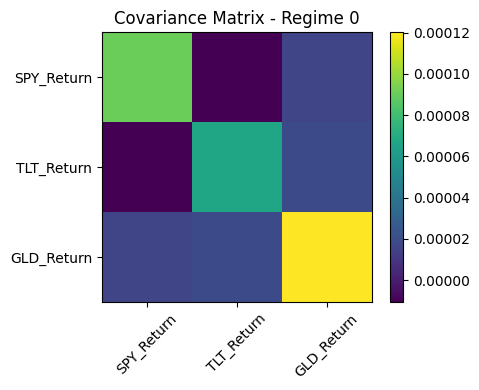

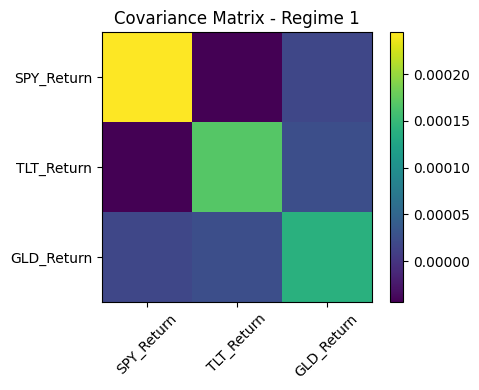

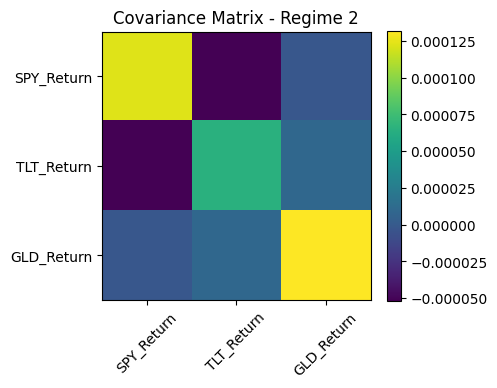

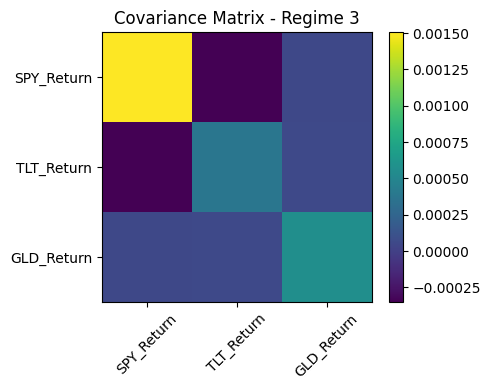

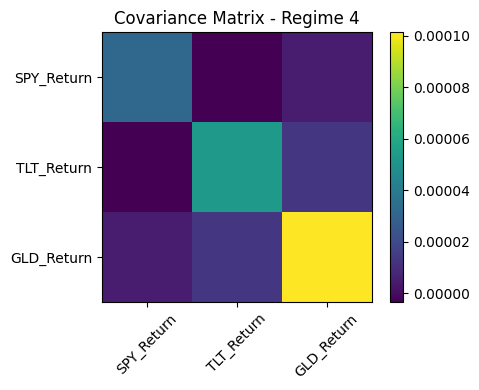

In [71]:
# Iterate through each regime's covariance matrix and visualize it as a heatmap
# This helps in understanding the relationships between assets in different market conditions
for regime, cov in regime_covariance.items():

    plt.figure(figsize=(5,4))
    plt.imshow(cov, interpolation="nearest")
    plt.colorbar()
    plt.xticks(range(len(cov.columns)), cov.columns, rotation=45)
    plt.yticks(range(len(cov.columns)), cov.columns)
    plt.title(f"Covariance Matrix - Regime {regime}")
    plt.tight_layout()
    plt.show()

In [72]:
# Define a function to calculate the negative Sharpe ratio of a portfolio
# This function will be used as the objective function for portfolio optimization
def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate=0):

    # Portfolio expected return
    portfolio_return = np.dot(weights, mean_returns)

    # Portfolio volatility
    portfolio_volatility = np.sqrt(
        np.dot(weights.T,
               np.dot(cov_matrix, weights)))

    # Avoid division by zero
    if portfolio_volatility == 0:
        return np.inf

    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return -sharpe_ratio

In [73]:
# Determine the number of assets in the portfolio
# Initialize equal weights for all assets as a starting point for optimization
n_assets = len(portfolio_assets)
initial_weights = np.ones(n_assets) / n_assets

In [74]:
# Define constraints for the optimization: the sum of weights must equal 1
constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)

In [75]:
# Define bounds for the optimization: each asset's weight must be between 0 and 1 (inclusive)
bounds = tuple((0, 1) for _ in range(n_assets))

In [76]:
# Optimize Portfolio for each regime
# Iterate through each market regime, using its specific mean returns and covariance matrix
# to find the optimal asset weights that maximize the Sharpe ratio (by minimizing the negative Sharpe ratio)
# Store the optimization results for each regime

optimized_portfolios = {}

for regime in sorted(regime_mean_returns.keys()):
    mean_returns_for_regime = regime_mean_returns[regime]
    cov_matrix_for_regime = regime_covariance[regime]

    result = minimize(
        fun=negative_sharpe,
        x0=initial_weights,
        args=(mean_returns_for_regime, cov_matrix_for_regime),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints)

    optimized_portfolios[regime] = result

In [77]:
# Print the success status and message from the last portfolio optimization run
print(result.success)
print(result.message)

True
Optimization terminated successfully


In [78]:
# Extract and display the optimal weights from the last optimization result
optimal_weights = result.x
optimal_weights

array([0.83922472, 0.        , 0.16077528])

In [79]:
# Create a DataFrame to display the optimal weights for each asset
weights_table = pd.DataFrame({
    "Asset": ["SPY", "TLT", "GLD"],
    "Weight": optimal_weights
})

weights_table

,Asset,Weight
0,SPY,0.839225
1,TLT,0.000000
2,GLD,0.160775


In [80]:
# Calculate and display the sum of the optimal portfolio weights to verify it equals 1
weights_table["Weight"].sum()

np.float64(1.0)

In [81]:
# Calculate and display the minimum optimal portfolio weight
weights_table["Weight"].min()

0.0

In [82]:
# Define the selected regime (Regime 4 in this case) for which the optimal weights were derived
# Calculate the portfolio's expected return, volatility, and Sharpe ratio for this specific regime
selected_regime = 4 # Since optimal_weights were derived from the last regime (Regime 4)

portfolio_return = np.dot(
    optimal_weights,
    regime_mean_returns[selected_regime])

portfolio_volatility = np.sqrt(
    np.dot(
        optimal_weights.T,
        np.dot(regime_covariance[selected_regime], optimal_weights)))

portfolio_sharpe = (portfolio_return/portfolio_volatility)

In [83]:
# Print the calculated expected return, volatility, and Sharpe ratio of the optimized portfolio
print(f"Expected Return : {portfolio_return:.6f}")
print(f"Volatility      : {portfolio_volatility:.6f}")
print(f"Sharpe Ratio    : {portfolio_sharpe:.4f}")

Expected Return : 0.000724
Volatility      : 0.005135
Sharpe Ratio    : 0.1410


In [84]:
# Encapsulate the portfolio optimization logic into a reusable function
# This function takes mean returns, covariance matrix, and an optional risk-free rate as input
# It returns the result object from the optimization process
def optimize_portfolio(mean_returns,
                       cov_matrix,
                       risk_free_rate=0):

    n_assets = len(mean_returns)

    initial_weights = np.ones(n_assets) / n_assets

    constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)

    bounds = tuple((0, 1) for _ in range(n_assets))

    result = minimize(
        negative_sharpe,
        initial_weights,
        args=(mean_returns,
              cov_matrix,
              risk_free_rate),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints)

    return result

In [85]:
# Re-run the portfolio optimization for each regime using the newly defined `optimize_portfolio` function
# Store the results in the `optimized_portfolios` dictionary
optimized_portfolios = {}

for regime in regime_mean_returns.keys():

    result = optimize_portfolio(
        regime_mean_returns[regime],
        regime_covariance[regime]
    )

    optimized_portfolios[regime] = result

In [86]:
# Extract the optimal weights for each regime and store them in a list of pandas Series
# Combine these Series into a single DataFrame for easy comparison and display
weights = []

for regime, result in optimized_portfolios.items():

    weights.append(
        pd.Series(
            result.x,
            index=["SPY","TLT","GLD"],
            name=f"Regime {regime}"
        )
    )

weights_df = pd.DataFrame(weights)

weights_df

,SPY,TLT,GLD
Regime 0,1.000000e+00,0.000000,5.551115e-17
Regime 1,8.103726e-01,0.000000,1.896274e-01
Regime 2,3.191417e-01,0.607557,7.330111e-02
Regime 3,8.673617e-18,0.614137,3.858633e-01
Regime 4,8.392247e-01,0.000000,1.607753e-01


In [87]:
# Print the optimization success status and messages for each regime
# This helps in verifying if the optimization converged correctly for all regimes
for regime, result in optimized_portfolios.items():

    print(
        f"Regime {regime}:",
        result.success,
        result.message
    )

Regime 0: True Optimization terminated successfully
Regime 1: True Optimization terminated successfully
Regime 2: True Optimization terminated successfully
Regime 3: True Optimization terminated successfully
Regime 4: True Optimization terminated successfully


In [88]:
# Display the DataFrame of optimal weights, rounded to 3 decimal places for readability
weights_df.round(3)

,SPY,TLT,GLD
Regime 0,1.000,0.000,0.000
Regime 1,0.810,0.000,0.190
Regime 2,0.319,0.608,0.073
Regime 3,0.000,0.614,0.386
Regime 4,0.839,0.000,0.161


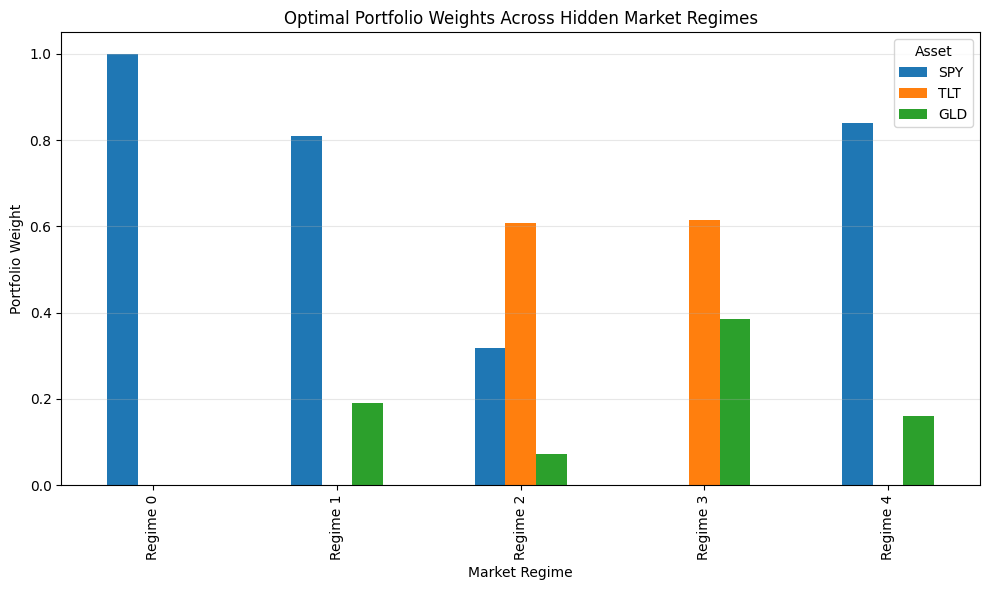

In [89]:
# Visualize the optimal portfolio weights for each asset across different market regimes using a bar chart
weights_df.plot(kind="bar", figsize=(10,6))

plt.title("Optimal Portfolio Weights Across Hidden Market Regimes")
plt.ylabel("Portfolio Weight")
plt.xlabel("Market Regime")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Asset")
plt.tight_layout()
plt.show()

In [90]:
# Calculate and summarize the expected return, volatility, and Sharpe ratio for the optimized portfolio in each regime
# Store these metrics in a DataFrame and display them, rounded to 4 decimal places
portfolio_summary = []

for regime in regime_mean_returns.keys():

    weights = optimized_portfolios[regime].x
    mu = regime_mean_returns[regime]
    sigma = regime_covariance[regime]

    port_return = np.dot(weights, mu)

    port_vol = np.sqrt(
        np.dot(weights.T,
               np.dot(sigma, weights)))

    sharpe = port_return / port_vol

    portfolio_summary.append({
        "Regime": regime,
        "Expected Return": port_return,
        "Volatility": port_vol,
        "Sharpe Ratio": sharpe})

portfolio_summary = pd.DataFrame(portfolio_summary)
portfolio_summary.round(4)

,Regime,Expected Return,Volatility,Sharpe Ratio
0,0,0.0004,0.0095,0.0397
1,1,0.0006,0.0131,0.0470
2,2,0.0006,0.0042,0.1347
3,3,0.0023,0.0159,0.1452
4,4,0.0007,0.0051,0.1410


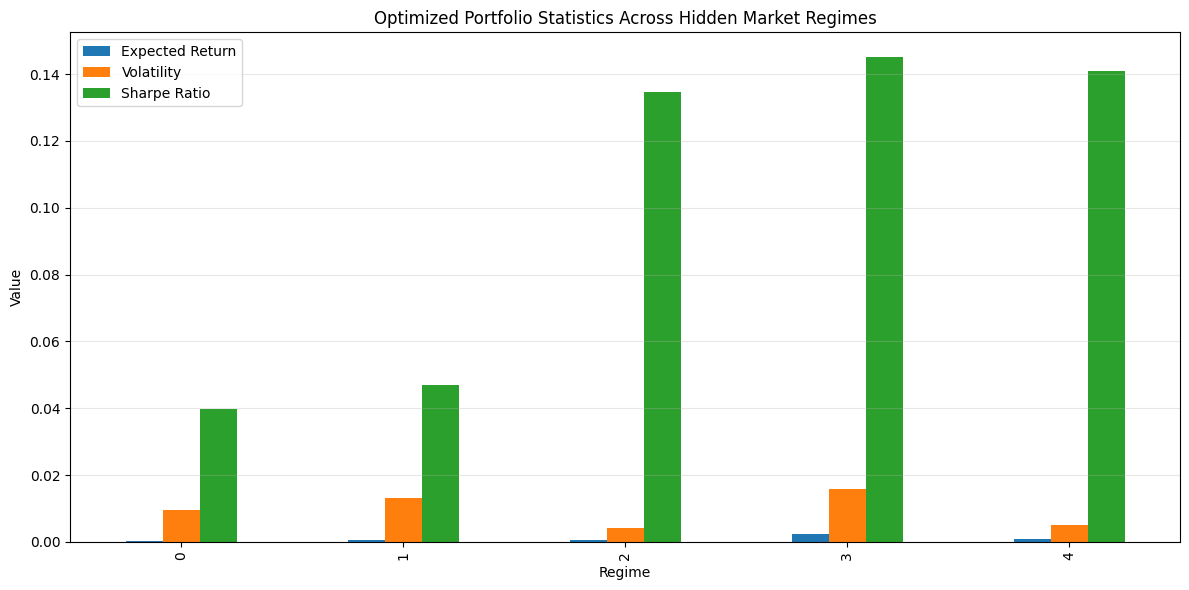

In [91]:
# Create a bar chart to visualize the optimized portfolio statistics (Expected Return, Volatility, Sharpe Ratio)
# across the different hidden market regimes, providing an overview of portfolio performance in each state
metrics = portfolio_summary.set_index("Regime")
metrics.plot(kind="bar", figsize=(12,6))

plt.title("Optimized Portfolio Statistics Across Hidden Market Regimes")
plt.ylabel("Value")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()